# Solver verification: Ritter dam break and steady Voellmy flow

This notebook verifies the finite-volume solver in `solver/core.py`, the **same module the web app runs** in the browser (it is imported here, not re-implemented).

System solved, with $U = [h, hu]$:

$$h_t + (hu)_x = 0, \qquad (hu)_t + \left(hu^2 + \tfrac12 g\cos\theta\, h^2\right)_x = g h \sin\theta - \mu g h \cos\theta\,\mathrm{sgn}(u) - \frac{g\,u|u|}{\xi}$$

Scheme: finite volume with a **flux-limited Lax-Wendroff** flux. At each interface the two-step (Richtmyer) Lax-Wendroff flux is blended with the Rusanov (local Lax-Friedrichs) flux, $F = F_\text{Rus} + \phi\,(F_\text{LW} - F_\text{Rus})$. The limiter $\phi \in [0,1]$ is 1 where $h$ and $hu$ are smooth and 0 at extrema, shocks and next to dry cells, where pure Lax-Wendroff oscillates and drives $h$ negative. Time step $\Delta t = C\,\Delta x / \max(|u| + \sqrt{g h \cos\theta})$, $C = 0.45$; sources by operator splitting (Coulomb as a projection to $u=0$, Voellmy drag backward-Euler).

| Section | Tests | Exercises |
|---|---|---|
| 1. Ritter dry-bed dam break | flux, CFL, dry front, conservation | $\theta = 0$, $\mu = 0$, $\xi = \infty$ (sources off) |
| 1d. Stoker wet-bed dam break | shock capturing: the flux limiter | same, but water downstream, so a shock forms |
| 2. Voellmy flow on a uniform slope | source terms | uniform state, so fluxes cancel exactly |

References: Ritter (1892) as compiled in SWASHES (Delestre et al., arXiv:1110.0288); Lax & Wendroff (1960); Richtmyer (1963); van Leer (1974); Rusanov (1961); Voellmy (1955); Savage & Hutter (1989); Toro, *Riemann Solvers and Numerical Methods for Fluid Dynamics*; LeVeque (2002).

In [1]:
import sys, pathlib
import numpy as np
import matplotlib.pyplot as plt

# import the real solver from the repository root
sys.path.insert(0, str(pathlib.Path.cwd().parent))
from solver import core

G = core.G
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
NUM_COLOR, EXACT_COLOR, GUIDE_COLOR = "#2a78d6", "#0b0b0b", "#8a8984"
print("CFL =", core.CFL, "  H_MIN =", core.H_MIN, "  g =", G)

CFL = 0.45   H_MIN = 1e-10   g = 9.81


## 0. Results derived here 

**Wave speeds.** With $q = hu$, the flux is $F = [q,\; q^2/h + \tfrac12 g\cos\theta\,h^2]$ and its Jacobian is
$$\frac{\partial F}{\partial U} = \begin{pmatrix} 0 & 1 \\ -u^2 + g h\cos\theta & 2u\end{pmatrix},$$
with eigenvalues $\lambda = u \pm \sqrt{g h \cos\theta}$. They are real and distinct for $h > 0$ (hyperbolic) and merge at the dry front $h = 0$.

**CFL step.** An explicit scheme must not let the fastest wave cross more than a fraction $C$ of a cell: $\Delta t = C\,\Delta x / \max(|u| + c)$, $c = \sqrt{g h\cos\theta}$.

**Terminal velocity.** For uniform flow ($\partial_x = 0$) the momentum equation reduces to $u_t = g(\sin\theta - \mu\cos\theta) - g u^2/(\xi h) \equiv A - B u^2$. Setting $u_t = 0$:
$$u_\infty = \sqrt{\xi h (\sin\theta - \mu\cos\theta)}, \qquad u(t) = u_\infty \tanh\!\left(\sqrt{AB}\,t\right) \text{ from rest.}$$
Units: $\xi$ in m/s², drag written as $g u|u|/\xi$ per unit area (after dividing by $\rho$) in the $hu$ equation; papers differ on this convention.

## 1. Ritter dry-bed dam break

**Setup.** Flat bed, no friction, $h = h_0 = 1$ m for $x < 0$, dry for $x > 0$, at rest; domain $[-10, 10]$ m with open boundaries (no wave reaches them by $t = 1$ s).

**Exact solution** ($c_0 = \sqrt{g h_0}$):
$h = h_0$ for $x < -c_0 t$; $\; h = (2c_0 - x/t)^2/(9g)$, $u = \tfrac23 (c_0 + x/t)$ for $-c_0 t \le x \le 2c_0 t$; $\; h = 0$ beyond the front $x = 2 c_0 t$.

**Expected.** Numerical curves follow the exact rarefaction, with the corner at the head ($x = -c_0 t$) slightly rounded and the front smeared over several cells, because the limiter falls back to first order at the kink and next to dry cells. **A failure** would show as a wrong front speed (flux or wave-speed error), oscillations (instability), or negative depth.

In [2]:
H0, X_MIN, X_MAX = 1.0, -10.0, 10.0
C0 = np.sqrt(G * H0)

def ritter_exact(x, t):
    s = x / t
    h = np.where(s < -C0, H0, np.where(s > 2 * C0, 0.0, (2 * C0 - s) ** 2 / (9 * G)))
    u = np.where((s >= -C0) & (s <= 2 * C0), 2 / 3 * (C0 + s), 0.0)
    return h, u

def run_ritter(n, t_end):
    # dam break with the real solver: theta = 0 everywhere, mu = 0, xi = inf
    dx = (X_MAX - X_MIN) / n
    x = X_MIN + (np.arange(n) + 0.5) * dx
    h, hu = np.where(x < 0, H0, 0.0), np.zeros(n)
    m0 = h.sum() * dx
    h, hu, _, out_l, out_r = core.run_until(h, hu, 0.0, t_end, dx, core.uniform_bed(n, 0.0),
                                            0.0, np.inf, ("open", "open"))
    mass_err = abs(h.sum() * dx + out_l + out_r - m0) / m0
    return x, dx, h, core.velocity(h, hu), mass_err

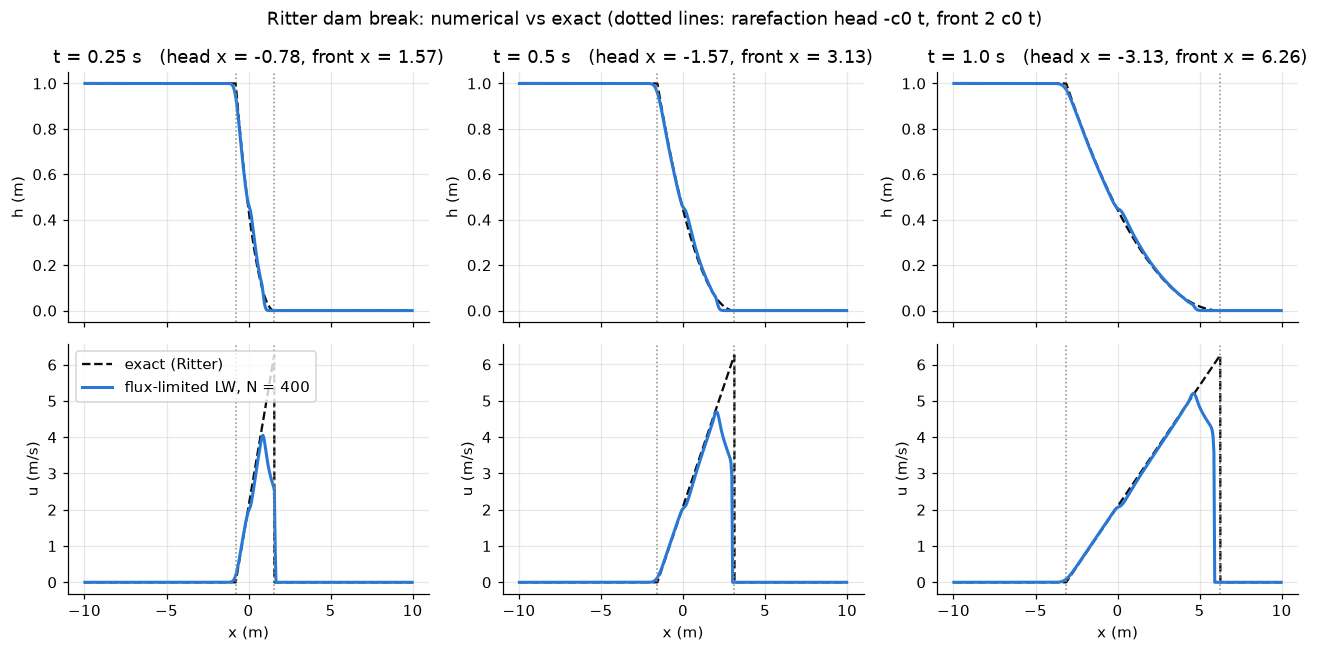

In [3]:
N_PLOT = 400
fig, axes = plt.subplots(2, 3, figsize=(12, 6), sharex=True)
xf = np.linspace(X_MIN, X_MAX, 2000)
for j, t in enumerate([0.25, 0.5, 1.0]):
    x, dx, h, u, _ = run_ritter(N_PLOT, t)
    he, ue = ritter_exact(xf, t)
    for ax, num, ex, lab in [(axes[0, j], h, he, "h (m)"), (axes[1, j], u, ue, "u (m/s)")]:
        ax.plot(xf, ex, color=EXACT_COLOR, lw=1.5, ls="--", label="exact (Ritter)")
        ax.plot(x, num, color=NUM_COLOR, lw=2, label=f"flux-limited LW, N = {N_PLOT}")
        for xm, name in [(-C0 * t, "head"), (2 * C0 * t, "front")]:
            ax.axvline(xm, color=GUIDE_COLOR, lw=1, ls=":")
        ax.set_ylabel(lab)
    axes[0, j].set_title(f"t = {t} s   (head x = {-C0*t:.2f}, front x = {2*C0*t:.2f})")
    axes[1, j].set_xlabel("x (m)")
axes[1, 0].legend(loc="upper left")
fig.suptitle("Ritter dam break: numerical vs exact (dotted lines: rarefaction head -c0 t, front 2 c0 t)")
fig.tight_layout()

**Reading the plot.** The depth tracks the parabola closely, and the head corner is only slightly rounded. Two visible errors:

1. **The front.** Over the last stretch before $x = 2c_0 t$, where the exact layer is only millimetres thick, the computed velocity falls below the exact $u \to 2c_0$ and drops to zero short of the exact front. There the limiter is forced to the first-order Rusanov flux (next to dry cells), whose dissipation ($\sim\tfrac12 a\,\Delta x$) dominates a vanishingly thin layer. Because $h$ is tiny there, this costs little in the depth error but is clearly visible in $u$.
2. **A small kink at $x = 0$.** This is the sonic point of the rarefaction, where $u = c$ ($u = \tfrac23 c_0 \approx 2.09$ m/s). Lax-Wendroff-type schemes are known to produce a glitch at a transonic rarefaction, and the limiter does not remove it completely. It stays at the same place and size as $t$ grows, and the refinement study below shows it does not prevent convergence. The pure Rusanov scheme did not show it.

### 1b. Grid refinement at fixed CFL

**What is tested.** $L_1$, $L_2$ and max errors of $h$ at $t = 1$ s as $\Delta x$ is halved ($N = 100 \to 3200$), with $C = 0.45$ fixed.

**Expected.** Errors decrease steadily. Lax-Wendroff would give rate 2 on a smooth solution, but Ritter has kinks at the head and at the front, where $h$ meets zero with zero slope but $u$ jumps. There the limiter switches to the first-order Rusanov flux, so the observed rate should sit **below 1**, but above that of a pure Rusanov scheme. CLAUDE.md's prototype reference for first-order Rusanov is L2 rates 0.54 → 0.72. The slope-1 line is a guide, not a pass criterion. **A failure** would be errors that stall or grow under refinement.

In [4]:
Ns = np.array([100, 200, 400, 800, 1600, 3200])
L1, L2, Linf, MASS = [], [], [], []
for n in Ns:
    x, dx, h, u, merr = run_ritter(n, 1.0)
    he, _ = ritter_exact(x, 1.0)
    e = h - he
    L1.append(np.sum(np.abs(e)) * dx); L2.append(np.sqrt(np.sum(e**2) * dx)); Linf.append(np.max(np.abs(e)))
    MASS.append(merr)
L1, L2, Linf, MASS = map(np.array, (L1, L2, Linf, MASS))
dxs = (X_MAX - X_MIN) / Ns
rate = lambda e: np.log2(e[:-1] / e[1:])

print(f"{'N':>6} {'dx':>8} {'L1':>10} {'rate':>6} {'L2':>10} {'rate':>6} {'Linf':>10} {'rate':>6} {'mass err':>10}")
for k, n in enumerate(Ns):
    r1 = f"{rate(L1)[k-1]:6.2f}" if k else "      "
    r2 = f"{rate(L2)[k-1]:6.2f}" if k else "      "
    ri = f"{rate(Linf)[k-1]:6.2f}" if k else "      "
    print(f"{n:6d} {dxs[k]:8.4f} {L1[k]:10.3e} {r1} {L2[k]:10.3e} {r2} {Linf[k]:10.3e} {ri} {MASS[k]:10.1e}")

     N       dx         L1   rate         L2   rate       Linf   rate   mass err
   100   0.2000  2.535e-01         9.572e-02         6.343e-02           0.0e+00
   200   0.1000  1.442e-01   0.81  5.795e-02   0.72  4.335e-02   0.55    0.0e+00
   400   0.0500  7.909e-02   0.87  3.300e-02   0.81  2.806e-02   0.63    0.0e+00
   800   0.0250  4.243e-02   0.90  1.822e-02   0.86  1.774e-02   0.66    0.0e+00
  1600   0.0125  2.235e-02   0.92  9.903e-03   0.88  1.197e-02   0.57    0.0e+00
  3200   0.0063  1.162e-02   0.94  5.323e-03   0.90  7.609e-03   0.65    0.0e+00


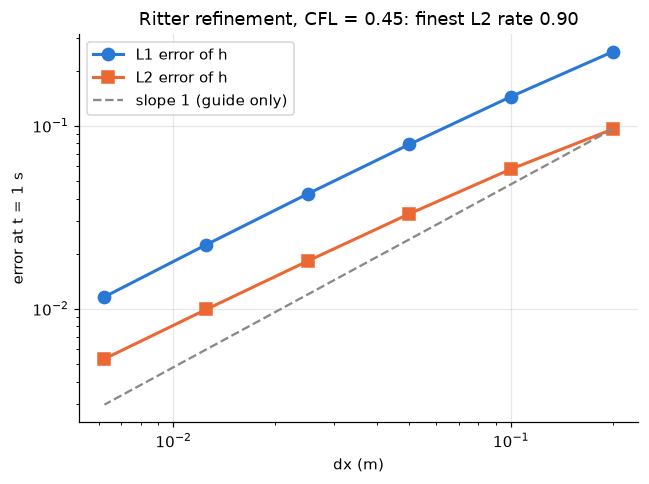

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(dxs, L1, "o-", color=NUM_COLOR, lw=2, ms=8, label="L1 error of h")
ax.loglog(dxs, L2, "s-", color="#eb6834", lw=2, ms=8, label="L2 error of h")
ax.loglog(dxs, L2[0] * (dxs / dxs[0]), color=GUIDE_COLOR, ls="--", lw=1.5, label="slope 1 (guide only)")
ax.set_xlabel("dx (m)"); ax.set_ylabel("error at t = 1 s")
ax.set_title(f"Ritter refinement, CFL = {core.CFL}: finest L2 rate {rate(L2)[-1]:.2f}")
ax.legend(); fig.tight_layout()

**Interpretation.** The measured $L_2$ rate rises with refinement from about 0.7 toward 0.9, and the errors are 2 to 2.3 times smaller than the first-order Rusanov prototype in `CLAUDE.md` (rates 0.54 → 0.72) at the same grid. The rate still stays below 1. Away from the front the Lax-Wendroff flux is active and accurate. The remaining error is concentrated where the limiter has switched to Rusanov: the head kink and especially the dry front (it is forced to first order within $H_\text{DRY}$ = 1 mm of a dry cell). The max error decreases more slowly still, because it is set by the cells right at the front. This is the known cost of limiting at a dry front, not a bug.

### 1c. Mass conservation

**What is tested.** $\sum h_i \Delta x$ plus boundary outflow should equal the initial mass to round-off, because the update is conservative ($U_i \mathrel{-}= \tfrac{\Delta t}{\Delta x}(F_{i+1/2} - F_{i-1/2})$) and the dry-front guard zeroes only $hu$, never $h$. **A failure** (error far above $10^{-14}$) would mean a non-conservative step, e.g. a positivity clip that removed mass.

In [6]:
print("relative mass error per grid:", ", ".join(f"{m:.1e}" for m in MASS))
print("max:", f"{MASS.max():.1e}")

relative mass error per grid: 0.0e+00, 0.0e+00, 0.0e+00, 0.0e+00, 0.0e+00, 0.0e+00
max: 0.0e+00


### 1d. Wet-bed dam break (Stoker): a shock

**Why this test.** Ritter has no shock: it is one smooth rarefaction. Pure, unlimited Lax-Wendroff passes Ritter, yet it blew up on the app's runout, because the flow forms a bore (a shock) where it piles up at the slope break. So Ritter cannot test the flux limiter. With water already downstream ($h_R > 0$), the dam break produces a real shock that the limiter must capture without Lax-Wendroff's oscillations.

**Setup.** Same as Ritter but $h_L = 1$ m, $h_R = 0.1$ m. Flat bed, no friction, open boundaries, $t = 1$ s.

**Exact solution** (derived here; the same structure is compiled in SWASHES). A left-going rarefaction, a constant middle state $(h_m, u_m)$, and a right-going shock of speed $s$:
- rarefaction ($u + 2c$ constant): $u_m = 2(c_L - c_m)$
- shock (Rankine-Hugoniot for mass and momentum): $u_m = (h_m - h_R)\sqrt{g(h_m + h_R)/(2 h_m h_R)}$, $\; s = h_m u_m/(h_m - h_R)$

Setting the two expressions for $u_m$ equal gives one equation for $h_m$, solved by root finding. The solution is $h_L$ for $x < -c_L t$, the Ritter fan up to $x = (u_m - c_m) t$, then $h_m$ up to the shock at $x = s t$, then $h_R$.

**Expected.** The shock is smeared over a few cells but sits at $x = s t$, with no ripples on either side. The $L_1$ error converges at about rate 1. $L_2$ converges at most at rate ½ on average for a captured shock (the error is a jump of height $h_m - h_R$ over a width $\propto \Delta x$), with noise from where the exact jump falls inside a cell, so it is reported but not used as a criterion. **A failure** would be oscillations next to the shock (a missing or weak limiter), a shock at the wrong speed (a non-conservative or inconsistent flux), or $L_1$ not converging.

In [7]:
from scipy.optimize import brentq

HL_W, HR_W = 1.0, 0.1
CL_W = np.sqrt(G * HL_W)

def shock_mismatch(hm):
    # u_m from the rarefaction minus u_m from the shock; zero at the true middle depth
    return 2 * (CL_W - np.sqrt(G * hm)) - (hm - HR_W) * np.sqrt(G * (hm + HR_W) / (2 * hm * HR_W))

HM = brentq(shock_mismatch, HR_W, HL_W, xtol=1e-14)
UM = 2 * (CL_W - np.sqrt(G * HM))
S_SHOCK = HM * UM / (HM - HR_W)
CM = np.sqrt(G * HM)
print(f"h_m = {HM:.6f} m, u_m = {UM:.6f} m/s, shock speed s = {S_SHOCK:.6f} m/s")
print("Rankine-Hugoniot residuals (mass, momentum):",
      f"{S_SHOCK * (HM - HR_W) - HM * UM:.1e},",
      f"{S_SHOCK * HM * UM - (HM * UM**2 + 0.5 * G * (HM**2 - HR_W**2)):.1e}")

def stoker_exact(x, t):
    s = x / t
    h = np.where(s < -CL_W, HL_W, np.where(s < UM - CM, (2 * CL_W - s) ** 2 / (9 * G),
                                           np.where(s < S_SHOCK, HM, HR_W)))
    u = np.where(s < -CL_W, 0.0, np.where(s < UM - CM, 2 / 3 * (CL_W + s), np.where(s < S_SHOCK, UM, 0.0)))
    return h, u

def run_stoker(n, t_end):
    dx = (X_MAX - X_MIN) / n
    x = X_MIN + (np.arange(n) + 0.5) * dx
    h, hu = np.where(x < 0, HL_W, HR_W), np.zeros(n)
    m0 = h.sum() * dx
    h, hu, _, out_l, out_r = core.run_until(h, hu, 0.0, t_end, dx, core.uniform_bed(n, 0.0),
                                            0.0, np.inf, ("open", "open"))
    return x, dx, h, core.velocity(h, hu), abs(h.sum() * dx + out_l + out_r - m0) / m0

h_m = 0.396175 m, u_m = 2.321355 m/s, shock speed s = 3.105134 m/s
Rankine-Hugoniot residuals (mass, momentum): 0.0e+00, -4.4e-16


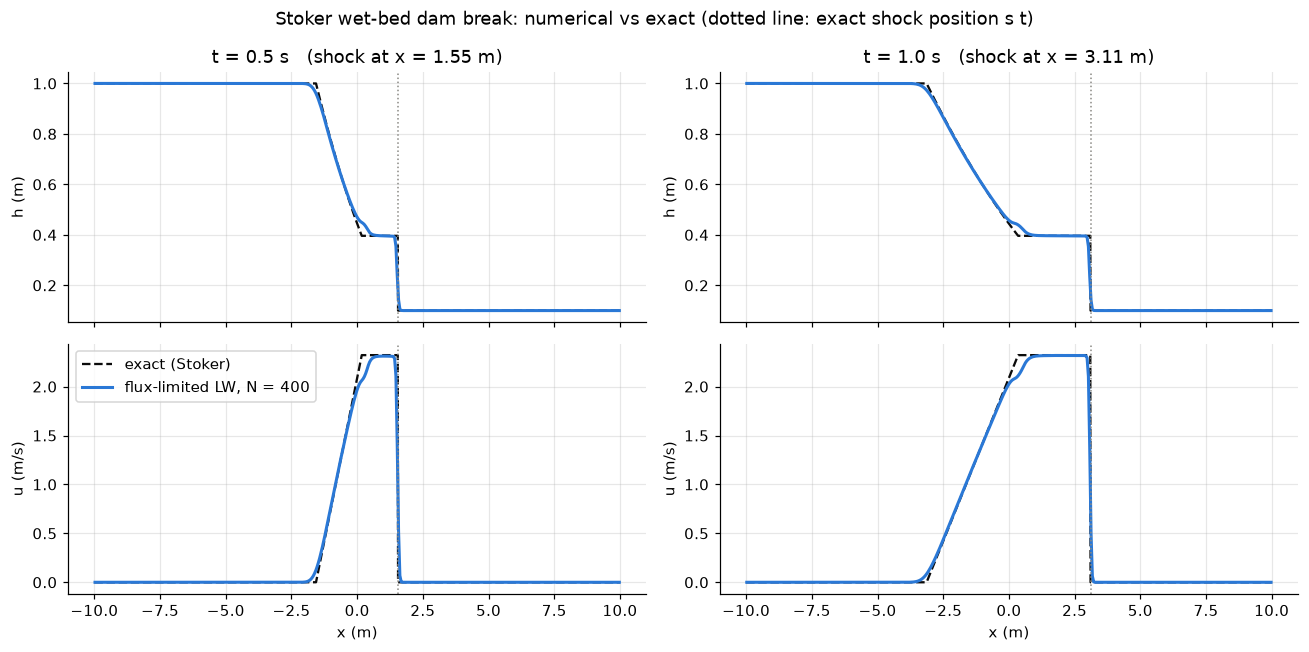

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for j, t in enumerate([0.5, 1.0]):
    x, dx, h, u, _ = run_stoker(N_PLOT, t)
    he, ue = stoker_exact(xf, t)
    for ax, num, ex, lab in [(axes[0, j], h, he, "h (m)"), (axes[1, j], u, ue, "u (m/s)")]:
        ax.plot(xf, ex, color=EXACT_COLOR, lw=1.5, ls="--", label="exact (Stoker)")
        ax.plot(x, num, color=NUM_COLOR, lw=2, label=f"flux-limited LW, N = {N_PLOT}")
        ax.axvline(S_SHOCK * t, color=GUIDE_COLOR, lw=1, ls=":")
        ax.set_ylabel(lab)
    axes[0, j].set_title(f"t = {t} s   (shock at x = {S_SHOCK * t:.2f} m)")
    axes[1, j].set_xlabel("x (m)")
axes[1, 0].legend(loc="upper left")
fig.suptitle("Stoker wet-bed dam break: numerical vs exact (dotted line: exact shock position s t)")
fig.tight_layout()

     N         L1   rate         L2   rate  shock err (cells)  max overshoot (m)  mass err
   100  2.115e-01         1.239e-01                     -0.48            5.4e-02   1.6e-16
   200  1.042e-01   1.02  7.031e-02   0.82              -0.62            3.8e-02   0.0e+00
   400  5.380e-02   0.95  4.767e-02   0.56              -0.71            1.2e-02   0.0e+00
   800  2.720e-02   0.98  3.124e-02   0.61              -0.76            2.9e-03   0.0e+00
  1600  1.351e-02   1.01  1.915e-02   0.71              -0.77            6.5e-04   0.0e+00
  3200  7.591e-03   0.83  1.849e-02   0.05              -0.80            1.9e-04   0.0e+00


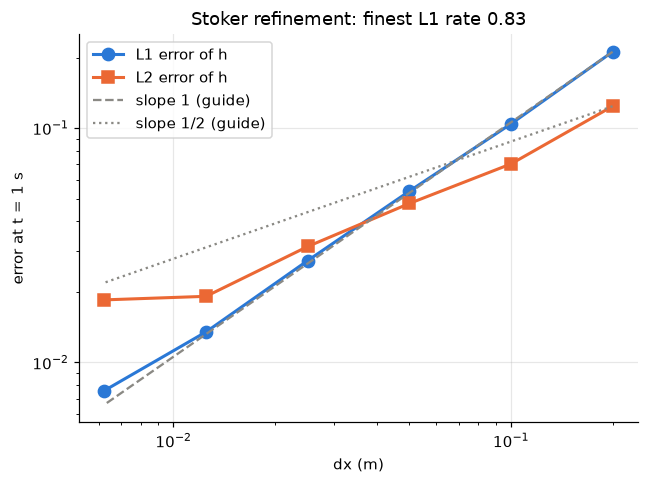

In [9]:
Ns_w = np.array([100, 200, 400, 800, 1600, 3200])
L1w, L2w, SHOCK_ERR, OVER, MASS_W = [], [], [], [], []
for n in Ns_w:
    x, dx, h, u, merr = run_stoker(n, 1.0)
    he, _ = stoker_exact(x, 1.0)
    L1w.append(np.sum(np.abs(h - he)) * dx); L2w.append(np.sqrt(np.sum((h - he) ** 2) * dx))
    # shock position: last crossing of the mid-jump depth (linear interpolation)
    h_mid = 0.5 * (HM + HR_W)
    j = np.nonzero(h >= h_mid)[0][-1]
    SHOCK_ERR.append((x[j] + (h[j] - h_mid) / (h[j] - h[j + 1]) * dx - S_SHOCK) / dx)
    plateau = (x > (UM - CM) + 0.3) & (x < S_SHOCK - 0.3)
    OVER.append(max(h[plateau].max() - HM, HR_W - h[x > S_SHOCK].min()))
    MASS_W.append(merr)
L1w, L2w, SHOCK_ERR, OVER, MASS_W = map(np.array, (L1w, L2w, SHOCK_ERR, OVER, MASS_W))
dxw = (X_MAX - X_MIN) / Ns_w

print(f"{'N':>6} {'L1':>10} {'rate':>6} {'L2':>10} {'rate':>6} {'shock err (cells)':>18} {'max overshoot (m)':>18} {'mass err':>9}")
for k, n in enumerate(Ns_w):
    r1 = f"{rate(L1w)[k-1]:6.2f}" if k else "      "
    r2 = f"{rate(L2w)[k-1]:6.2f}" if k else "      "
    print(f"{n:6d} {L1w[k]:10.3e} {r1} {L2w[k]:10.3e} {r2} {SHOCK_ERR[k]:18.2f} {OVER[k]:18.1e} {MASS_W[k]:9.1e}")

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.loglog(dxw, L1w, "o-", color=NUM_COLOR, lw=2, ms=8, label="L1 error of h")
ax.loglog(dxw, L2w, "s-", color="#eb6834", lw=2, ms=8, label="L2 error of h")
ax.loglog(dxw, L1w[0] * (dxw / dxw[0]), color=GUIDE_COLOR, ls="--", lw=1.5, label="slope 1 (guide)")
ax.loglog(dxw, L2w[0] * (dxw / dxw[0]) ** 0.5, color=GUIDE_COLOR, ls=":", lw=1.5, label="slope 1/2 (guide)")
ax.set_xlabel("dx (m)"); ax.set_ylabel("error at t = 1 s")
ax.set_title(f"Stoker refinement: finest L1 rate {rate(L1w)[-1]:.2f}")
ax.legend(); fig.tight_layout()

**Interpretation.**
- **Shock position.** The captured shock trails the exact one by a nearly constant 0.5–0.8 of a cell, so in metres the error shrinks in proportion to $\Delta x$. The shock speed is right, which means the flux is conservative and consistent.
- **No oscillations.** Ahead of the shock the depth never drops below $h_R$. The overshoot on the plateau behind it is a small fraction of the jump (1.9e-4 m against a jump of 0.30 m at $N = 3200$) and shrinks under refinement. This is what the limiter is for; pure Lax-Wendroff would produce ripples here.
- **$L_1$** converges at about rate 1, the best a shock-capturing scheme can do across a discontinuity.
- **$L_2$** flattens at the two finest grids. This is not a failure to converge. Splitting the error by region (done while building this test) shows that everywhere away from the shock the error keeps falling. Inside the 1 m around the shock it goes up and down with $N$ (6.9e-4, 2.7e-4, 3.1e-4, 2.0e-4 for $L_2^2$ at $N$ = 800 to 6400), because it depends on where the exact jump falls inside a cell. Over several refinements $L_2$ follows rate ½, as expected for a captured shock, which is why $L_1$, not $L_2$, is the pass criterion.
- The small bump where the rarefaction meets the plateau (near $x = 0.3$ m) is the sonic-point glitch seen in Ritter: here the end of the fan sits just right of the sonic point $x = 0$.

**What this does not cover.** This shock is in frictionless water on a flat bed. The bore in the app forms at the slope break, with Coulomb/Voellmy friction acting. Those were checked only for mass conservation and grid convergence of runout, not against an exact solution.

## 2. Voellmy flow on a uniform slope (source terms)

Ritter switches the sources off, so this section tests them. **Setup:** periodic domain, $\theta = 30°$, $\phi = 20°$ ($\mu = \tan\phi$), $\xi = 500$ m/s², uniform $h = 2$ m, released from rest. Since the state is uniform, the flux differences are exactly zero and only `apply_sources` acts.

**Expected.**
1. $u(t)$ follows $u_\infty \tanh(\sqrt{AB}\,t)$, with an $O(\Delta t)$ splitting error that shrinks as $\Delta t$ shrinks.
2. $u \to u_\infty = \sqrt{\xi h(\sin\theta - \mu\cos\theta)}$ to round-off, because backward Euler on the drag makes $u_\infty$ an exact fixed point of the step.

**A failure** would mean a wrong sign, a wrong placement of $\xi$, or a wrong friction coefficient in the source step.

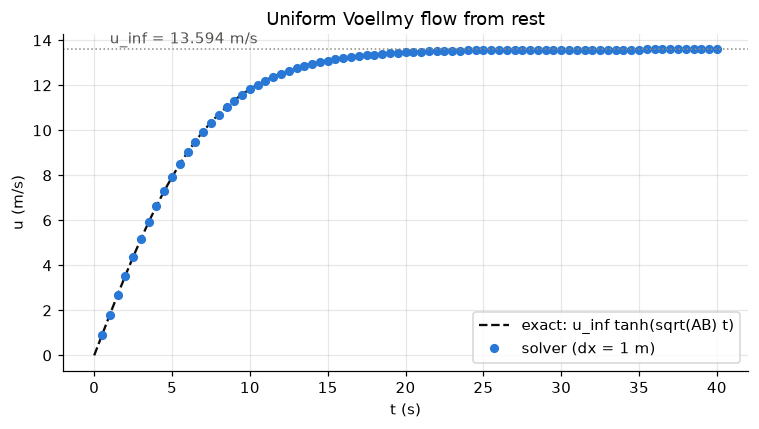

In [10]:
THETA, PHI, XI, HV = np.radians(30.0), np.radians(20.0), 500.0, 2.0
MU = np.tan(PHI)
A = G * (np.sin(THETA) - MU * np.cos(THETA))
B = G / (XI * HV)
U_INF = np.sqrt(XI * HV * (np.sin(THETA) - MU * np.cos(THETA)))
exact_u = lambda t: U_INF * np.tanh(np.sqrt(A * B) * t)
NV = 20
bed = core.uniform_bed(NV, THETA)
bc = ("periodic", "periodic")

def voellmy_history(dx, t_out):
    h, hu, t, us = np.full(NV, HV), np.zeros(NV), 0.0, []
    for tk in t_out:
        h, hu, t, _, _ = core.run_until(h, hu, t, tk, dx, bed, MU, XI, bc)
        us.append(hu[0] / h[0])
    return np.array(us)

t_out = np.linspace(0.5, 40.0, 80)
fig, ax = plt.subplots(figsize=(7, 4))
tt = np.linspace(0, 40, 400)
ax.plot(tt, exact_u(tt), color=EXACT_COLOR, ls="--", lw=1.5, label="exact: u_inf tanh(sqrt(AB) t)")
ax.plot(t_out, voellmy_history(1.0, t_out), "o", color=NUM_COLOR, ms=5, label="solver (dx = 1 m)")
ax.axhline(U_INF, color=GUIDE_COLOR, ls=":", lw=1)
ax.text(1, U_INF * 1.02, f"u_inf = {U_INF:.3f} m/s", color="#52514e")
ax.set_xlabel("t (s)"); ax.set_ylabel("u (m/s)"); ax.legend(loc="lower right")
ax.set_title("Uniform Voellmy flow from rest"); fig.tight_layout()

In [11]:
# transient error at t = 5 s as the CFL time step shrinks (dt ~ dx at fixed CFL)
print(f"{'dx':>6} {'rel. error at t=5 s':>20}")
errs_v = []
for dx in [1.0, 0.5, 0.25, 0.125]:
    e = abs(voellmy_history(dx, [5.0])[0] - exact_u(5.0)) / U_INF
    errs_v.append(e)
    print(f"{dx:6.3f} {e:20.2e}")
print("observed rates:", np.round(np.log2(np.array(errs_v[:-1]) / np.array(errs_v[1:])), 2))

u_long = voellmy_history(1.0, [150.0])[0]
term_err = abs(u_long - U_INF) / U_INF
print(f"\nterminal velocity: solver {u_long:.10f}, exact {U_INF:.10f}, rel. error {term_err:.1e}")

    dx  rel. error at t=5 s
 1.000             9.00e-04
 0.500             4.49e-04


 0.250             2.24e-04


 0.125             1.12e-04
observed rates: [1. 1. 1.]



terminal velocity: solver 13.5938416536, exact 13.5938416536, rel. error 2.1e-14


**Interpretation.** The transient error is small and shrinks about linearly with $\Delta t$ (first-order Lie splitting), and the terminal velocity matches $u_\infty$ to round-off. This test checks the source step only. The interaction of friction with the flux at a moving front is not covered by an exact solution here.

## Summary

In [12]:
rows = [
    ("Ritter: L2 error decreases under refinement", "all rates > 0.4", f"rates {np.round(rate(L2), 2)}", np.all(rate(L2) > 0.4)),
    ("Ritter: mass conservation", "rel. error < 1e-13", f"max {MASS.max():.1e}", MASS.max() < 1e-13),
    ("Stoker: L1 error converges", "all L1 rates > 0.7", f"rates {np.round(rate(L1w), 2)}", np.all(rate(L1w) > 0.7)),
    ("Stoker: shock position", "|error| < 2 cells", f"max {np.abs(SHOCK_ERR).max():.2f} cells", np.all(np.abs(SHOCK_ERR) < 2)),
    ("Stoker: no oscillations", "overshoot < 1% of jump (finest)", f"{OVER[-1]:.1e} m", OVER[-1] < 0.01 * (HM - HR_W)),
    ("Stoker: mass conservation", "rel. error < 1e-13", f"max {MASS_W.max():.1e}", MASS_W.max() < 1e-13),
    ("Voellmy: transient converges with dt", "error decreasing, finest < 1e-3",
     f"{errs_v[-1]:.1e}", errs_v[-1] < 1e-3 and np.all(np.diff(errs_v) < 0)),
    ("Voellmy: terminal velocity", "rel. error < 1e-10", f"{term_err:.1e}", term_err < 1e-10),
]
print(f"{'test':<42} {'tolerance':<34} {'measured':<28} result")
for name, tol, meas, ok in rows:
    print(f"{name:<42} {tol:<34} {meas:<28} {'PASS' if ok else 'FAIL'}")

test                                       tolerance                          measured                     result
Ritter: L2 error decreases under refinement all rates > 0.4                    rates [0.72 0.81 0.86 0.88 0.9 ] PASS
Ritter: mass conservation                  rel. error < 1e-13                 max 0.0e+00                  PASS
Stoker: L1 error converges                 all L1 rates > 0.7                 rates [1.02 0.95 0.98 1.01 0.83] PASS
Stoker: shock position                     |error| < 2 cells                  max 0.80 cells               PASS
Stoker: no oscillations                    overshoot < 1% of jump (finest)    1.9e-04 m                    PASS
Stoker: mass conservation                  rel. error < 1e-13                 max 1.6e-16                  PASS
Voellmy: transient converges with dt       error decreasing, finest < 1e-3    1.1e-04                      PASS
Voellmy: terminal velocity                 rel. error < 1e-10                 2.1e-14        

The same checks run automatically in `tests/test_verification.py` (in CI before every deploy), together with a closed-domain mass-conservation test on the app's two-reach bed.

**Not verified here:** the slope break of the two-reach bed, where the app's bore forms with friction acting (no exact solution; Stoker covers shock capturing on a flat, frictionless bed, and the slope break was checked only for mass conservation and grid convergence of runout), and any agreement with real debris flows. This is a verification of the numerics, not a validation of the model.